# 3. Résultats : tableaux, cartes et graphiques

Ce notebook présente les résultats calculés par le notebook 2 : statistiques des délais, comparaison des départements, lien avec les incendies, communes prioritaires, cartes statiques et cartes interactives.

## 0. Mise en place

In [1]:
import os
import sys

# je cherche la racine du projet (le dossier qui contient "modules")
racine_projet = None
for essai in [".", "..", "../.."]:
    if os.path.exists(os.path.join(essai, "modules")) and racine_projet is None:
        racine_projet = os.path.abspath(essai)
print("Racine du projet :", racine_projet)

# j'ajoute la racine aux endroits où Python cherche les modules
if racine_projet not in sys.path:
    sys.path.append(racine_projet)

# si je modifie un module, il est rechargé automatiquement
%load_ext autoreload
%autoreload 2

Racine du projet : c:\Users\User\Documents\Python\Groupe_KC_AHA_Python


In [2]:
import pandas as pd
import geopandas as gpd

from modules.intern.Accessibility_temps_de_secours import parametres as p
from modules.intern.Accessibility_temps_de_secours import graphiques, cartes_interactives

## 1. Lecture des données et des résultats

In [3]:
communes = gpd.read_file("sorties/donnees_preparees.gpkg", layer="communes")
casernes = gpd.read_file("sorties/donnees_preparees.gpkg", layer="casernes")
forets = gpd.read_file("sorties/donnees_preparees.gpkg", layer="forets")
incendies = pd.read_csv("sorties/incendies_paca.csv", sep=";", dtype={"Code INSEE": str, "dep": str})

forets_communes = gpd.read_file("sorties/resultats.gpkg", layer="forets_communes")
carte_communes = gpd.read_file("sorties/resultats.gpkg", layer="carte_communes")

communes_avec_foret = carte_communes[carte_communes["nb_forets"] > 0]
seuil_incendies = communes_avec_foret["nb_incendies"].median()
seuil_delai = communes_avec_foret["delai_moyen"].median()

## 2. Statistiques des délais

### 2.1 Distribution des délais (toutes les forêts)

In [4]:
tableau_desc = forets_communes[["distance_km", "delai_min"]].describe()
tableau_desc.to_csv("sorties/stats_delais.csv")
graphiques.joli_tableau(tableau_desc, "Distances et délais d'accès aux forêts", couleurs="Blues")

,distance_km,delai_min
count,"109,498.0","109,498.0"
mean,5.0,7.8
std,2.7,4.2
min,0.0,0.0
25%,2.9,4.6
50%,4.6,7.2
75%,6.6,10.4
max,18.4,28.8


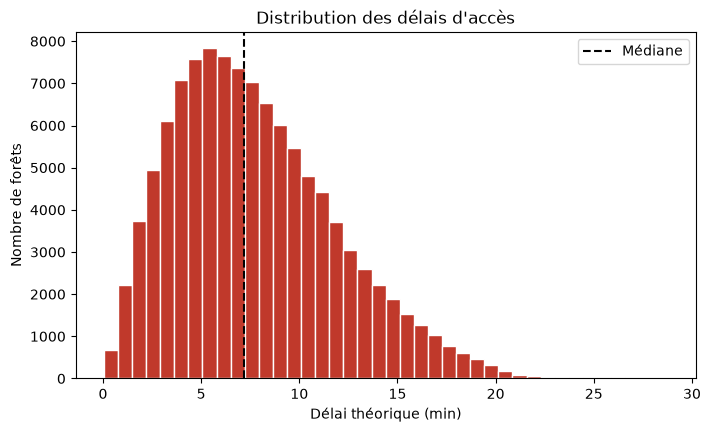

In [5]:
graphiques.histogramme(forets_communes["delai_min"], "Distribution des délais d'accès",
                       "Délai théorique (min)", "Nombre de forêts", mediane=True,
                       fichier="sorties/histogramme_delais.png")

### 2.2 Part des forêts par classe de délai

In [6]:
# reindex : je remets les classes dans l'ordre logique (et pas par ordre alphabétique)
tableau_classes = forets_communes["classe_delai"].value_counts().reindex(p.NOMS_CLASSES_DELAI).fillna(0).to_frame("nb_forets")
tableau_classes["part_%"] = tableau_classes["nb_forets"] / tableau_classes["nb_forets"].sum() * 100
tableau_classes.to_csv("sorties/classes_delai.csv")
graphiques.joli_tableau(tableau_classes, "Part des forêts par classe de délai", couleurs="Reds", colonnes=["part_%"])

,nb_forets,part_%
classe_delai,,
Moins de 10 min,"79,616.0",72.7
10 à 20 min,"29,275.0",26.7
20 à 30 min,607.0,0.6
Plus de 30 min,0.0,0.0


### 2.3 Comparaison des départements

In [7]:
tableau_dep = forets_communes.groupby(p.COL_DEP).agg(
    nb_forets=("id_foret", "count"),
    delai_moyen=("delai_min", "mean"),
    delai_median=("delai_min", "median"),
    delai_max=("delai_min", "max")
)
tableau_dep["nb_incendies"] = incendies.groupby("dep").size()
tableau_dep.to_csv("sorties/stats_departements.csv")
graphiques.joli_tableau(tableau_dep, "Délais d'accès par département", couleurs="YlOrRd",
                        colonnes=["delai_moyen", "delai_median", "delai_max"])

,nb_forets,delai_moyen,delai_median,delai_max,nb_incendies
dep,,,,,
04,"29,167.0",9.2,8.8,22.9,594.0
05,"23,006.0",8.6,8.0,28.8,238.0
06,"16,025.0",6.7,6.2,20.2,844.0
13,"11,099.0",5.6,5.2,21.9,"2,699.0"
83,"20,086.0",7.0,6.7,18.5,"1,136.0"
84,"10,115.0",7.2,6.4,20.6,429.0


## 3. Lien entre incendies et délai

Corrélation de Spearman (incendies, délai moyen) : -0.268


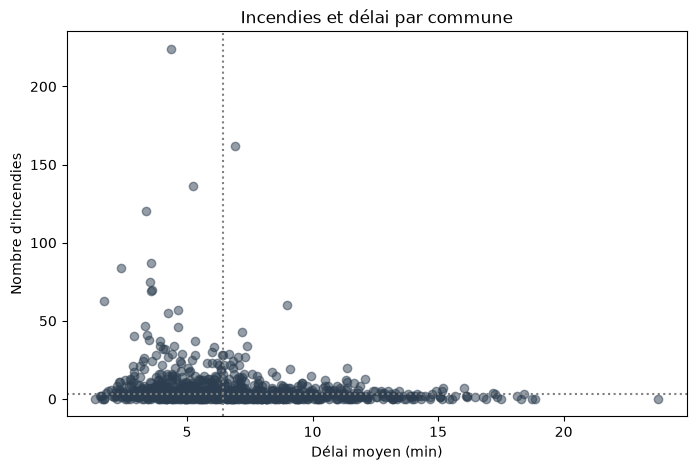

In [8]:
correlation = communes_avec_foret["nb_incendies"].corr(communes_avec_foret["delai_moyen"], method="spearman")
print("Corrélation de Spearman (incendies, délai moyen) :", round(correlation, 3))

graphiques.nuage_de_points(communes_avec_foret["delai_moyen"], communes_avec_foret["nb_incendies"],
                           "Incendies et délai par commune", "Délai moyen (min)", "Nombre d'incendies",
                           seuil_x=seuil_delai, seuil_y=seuil_incendies, fichier="sorties/nuage_incendies_delai.png")

J'utilise **Spearman** plutôt que Pearson parce que le nombre d'incendies est très asymétrique : quelques communes en concentrent énormément. Spearman travaille sur les rangs, il est moins sensible à ces valeurs extrêmes. Les lignes pointillées sont les médianes qui définissent la typologie.

## 4. Typologie et communes prioritaires

In [9]:
print(carte_communes["typologie"].value_counts())

top10 = carte_communes[carte_communes["typologie"] == "Prioritaire"]
top10 = top10.sort_values("nb_incendies", ascending=False).head(10)
top10 = top10[[p.COL_NOM, p.COL_DEP, "nb_incendies", "nb_forets", "delai_moyen", "delai_max"]].set_index(p.COL_NOM)
top10.to_csv("sorties/top10_prioritaires.csv")
graphiques.joli_tableau(top10, "Top 10 des communes prioritaires", couleurs="Reds",
                        colonnes=["nb_incendies", "delai_moyen"])

typologie
Éloignée, peu de feux     317
Exposée mais desservie    260
Faible enjeu              211
Prioritaire               154
Pas de forêt                2
Name: count, dtype: int64


,dep,nb_incendies,nb_forets,delai_moyen,delai_max
nom,,,,,
Aix-en-Provence,13,162.0,582.0,6.9,13.1
Lançon-Provence,13,60.0,213.0,9.0,13.3
Cabriès,13,43.0,138.0,7.2,11.5
Le Rove,13,34.0,43.0,7.4,8.8
Roquebrune-sur-Argens,83,29.0,321.0,6.7,11.9
Jouques,13,28.0,397.0,6.4,12.0
Saint-Chamas,13,27.0,87.0,7.3,11.8
Digne-les-Bains,04,27.0,594.0,7.0,14.5
Courmes,06,24.0,39.0,6.8,8.7


## 5. Cartes statiques

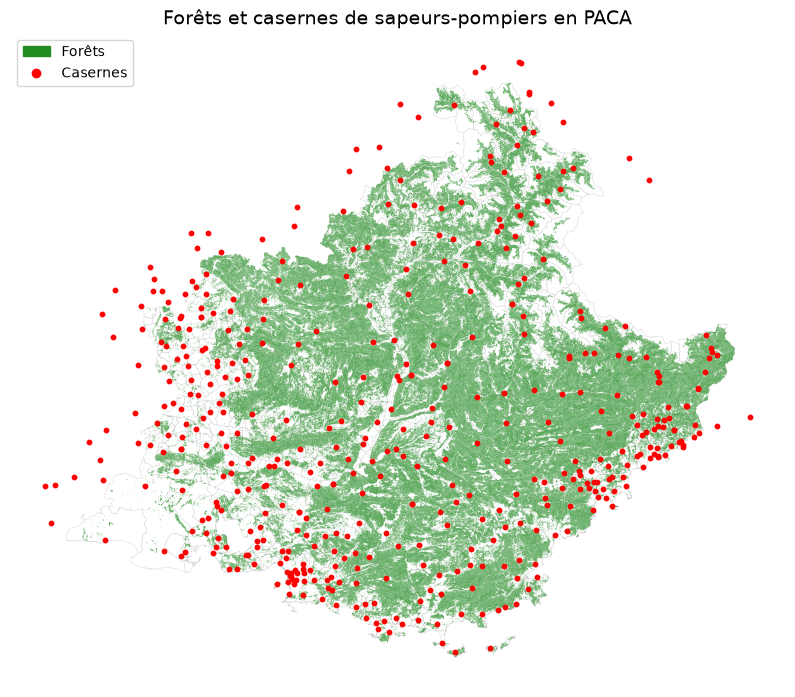

In [10]:
graphiques.carte_forets_casernes(communes, forets, casernes, fichier="sorties/carte1_forets_casernes.png")

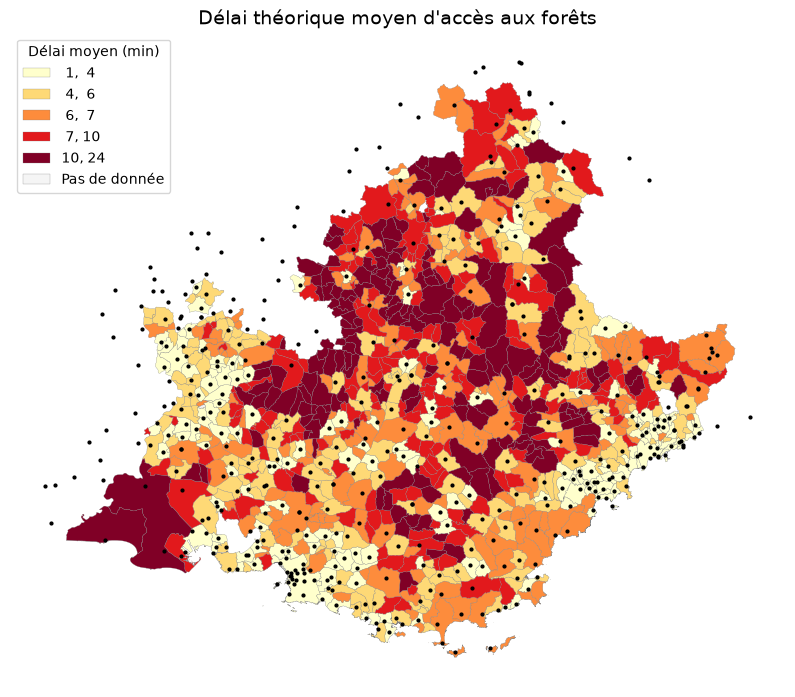

In [11]:
graphiques.carte_choroplethe(carte_communes, "delai_moyen", "Délai théorique moyen d'accès aux forêts",
                             "Délai moyen (min)", couleurs="YlOrRd", points=casernes,
                             fichier="sorties/carte2_delai_moyen.png")

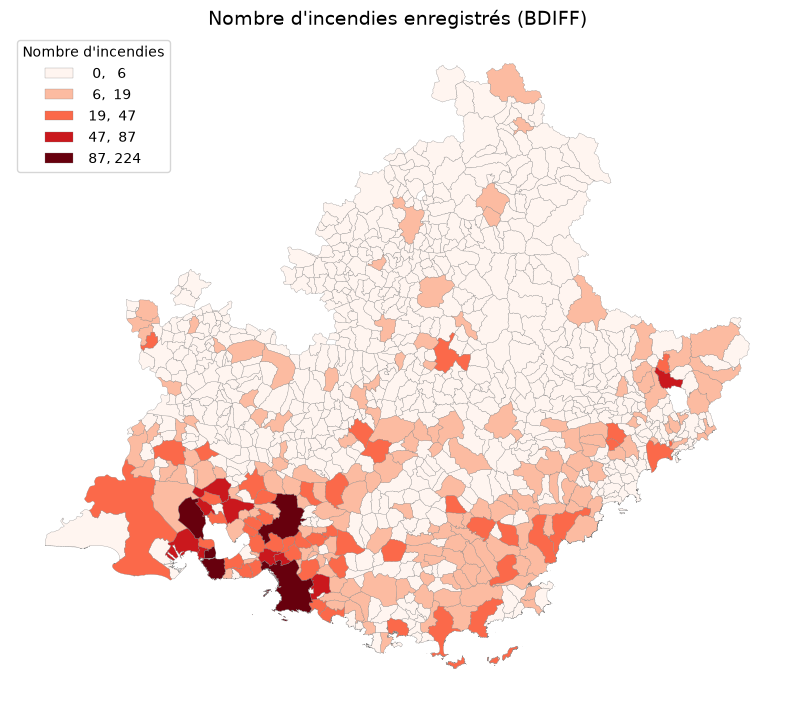

In [12]:
graphiques.carte_choroplethe(carte_communes, "nb_incendies", "Nombre d'incendies enregistrés (BDIFF)",
                             "Nombre d'incendies", couleurs="Reds", methode="natural_breaks",
                             fichier="sorties/carte3_incendies.png")

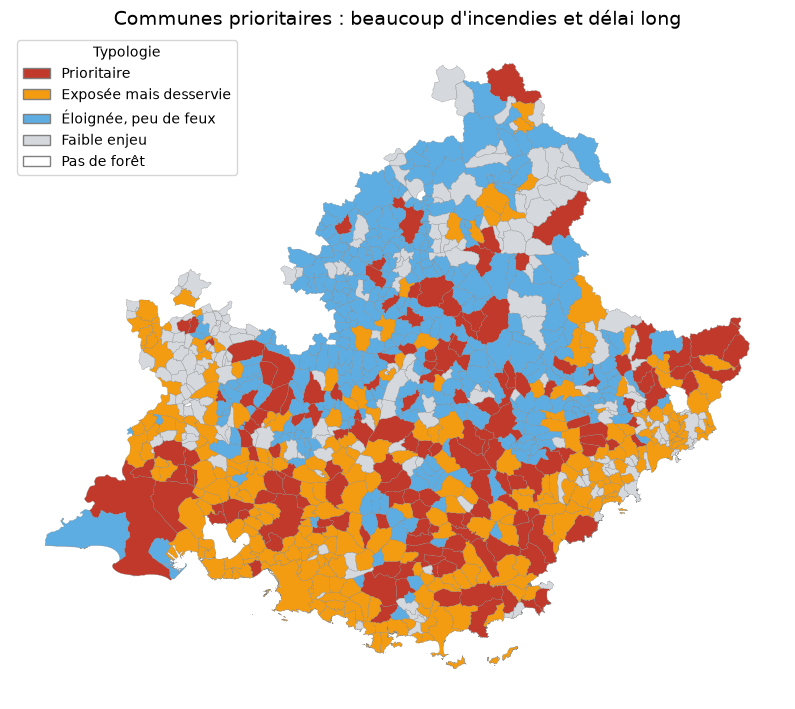

In [13]:
graphiques.carte_categories(carte_communes, "typologie", p.COULEURS_TYPOLOGIE,
                            "Communes prioritaires : beaucoup d'incendies et délai long", "Typologie",
                            fichier="sorties/carte4_typologie.png")

## 6. Cartes interactives (Folium)

On peut zoomer, survoler une commune pour voir ses chiffres, et **cocher ou décocher chaque couche** dans le menu en haut à droite. Les cartes sont aussi enregistrées en `.html` : elles s'ouvrent dans n'importe quel navigateur.

In [14]:
communes_web = cartes_interactives.preparer_pour_folium(carte_communes)
communes_web["delai_moyen"] = communes_web["delai_moyen"].round(1)

# les 200 forêts les plus éloignées d'une caserne
forets_loin = forets_communes.sort_values("delai_min", ascending=False).head(200)
forets_loin = forets_loin[["nom_caserne", "delai_min", "surface_ha", p.COL_NOM, "geometry"]].round(1)

carte1 = cartes_interactives.carte_delais(communes_web, casernes, forets_loin, p.COL_NOM,
                                          fichier="sorties/carte_interactive_delais.html")
carte1

In [15]:
carte2 = cartes_interactives.carte_typologie(communes_web, casernes, p.COULEURS_TYPOLOGIE, p.COL_NOM,
                                             fichier="sorties/carte_interactive_typologie.html")
carte2

## 7. Limites
- **Distance à vol d'oiseau × 1,3** : c'est une approximation. Un calcul sur le réseau routier réel (OSRM, osmnx) serait plus juste, surtout en montagne (04, 05, 06).
- **Caserne la plus proche ≠ caserne qui intervient.** La disponibilité et les moyens des casernes ne sont pas pris en compte.
- **Un point par forêt** : pour les grands massifs, le délai jusqu'à la lisière est plus court que le délai jusqu'au point intérieur.
- **Qualité OSM** : certaines casernes peuvent être absentes ou mal étiquetées.